# Lab 9.6.1

In [1]:
# 9.6.1 Support Vector Classifier: simulate two classes
library(e1071)
set.seed(1)
x <- matrix(rnorm(20 * 2), ncol = 2)
y <- c(rep(-1, 10), rep(1, 10))
x[y == 1, ] <- x[y == 1, ] + 1

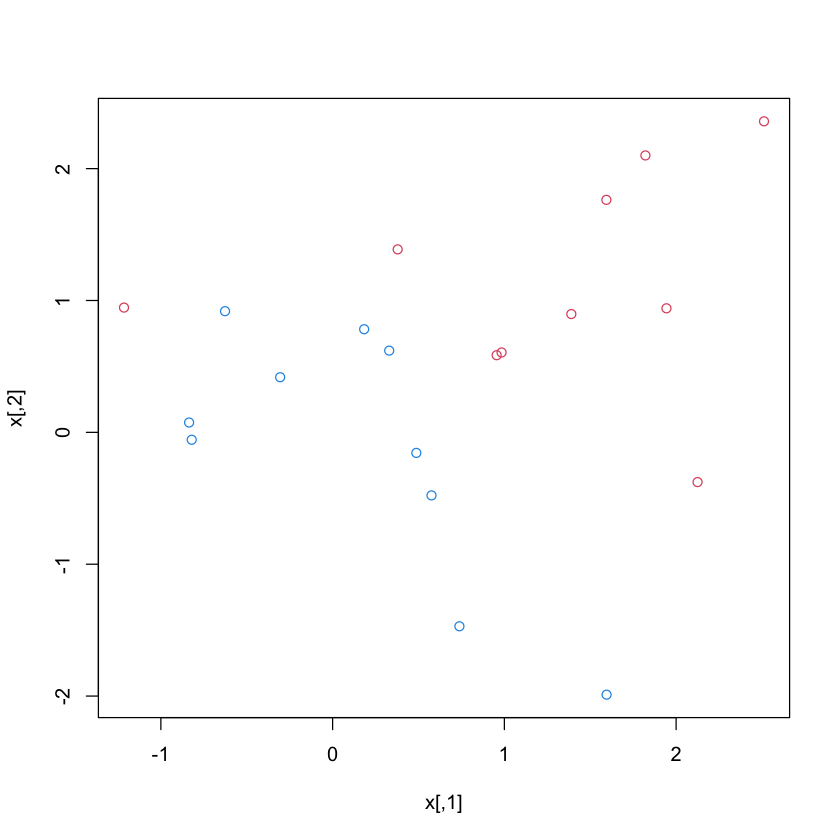

In [2]:
# Check whether the classes are linearly separable
plot(x, col = (3 - y))

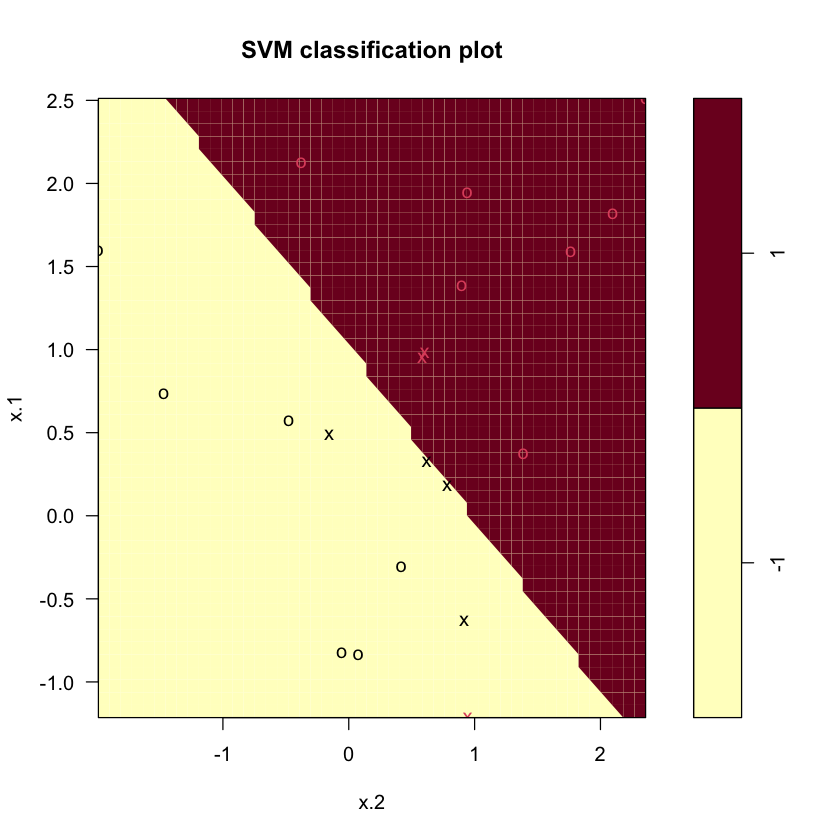

In [3]:
# Fit a support vector classifier with cost = 10
dat <- data.frame(x = x, y = as.factor(y))
svmfit <- svm(y ~ ., data = dat, kernel = "linear", cost = 10, scale = FALSE)
plot(svmfit, dat)

In [4]:
svmfit$index
summary(svmfit)

[1]  1  2  5  7 14 16 17


Call:
svm(formula = y ~ ., data = dat, kernel = "linear", cost = 10, scale = FALSE)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  10 

Number of Support Vectors:  7

 ( 4 3 )


Number of Classes:  2 

Levels: 
 -1 1




[1]  1  2  3  4  5  7  9 10 12 13 14 15 16 17 18 20

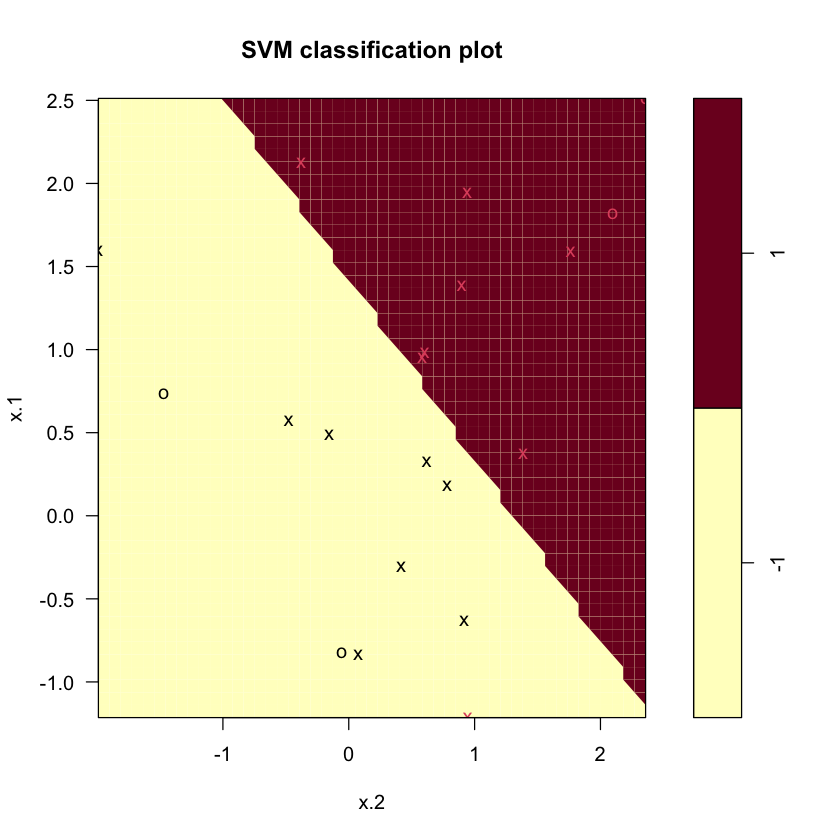

In [5]:
# Smaller cost -> wider margin, more support vectors
svmfit <- svm(y ~ ., data = dat, kernel = "linear", cost = 0.1, scale = FALSE)
plot(svmfit, dat)
svmfit$index

In [6]:
# 10-fold cross-validation over a range of cost values
set.seed(1)
tune.out <- tune(svm, y ~ ., data = dat, kernel = "linear",
                 ranges = list(cost = c(0.001, 0.01, 0.1, 1, 5, 10, 100)))
summary(tune.out)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost
  0.1

- best performance: 0.05 

- Detailed performance results:
   cost error dispersion
1 1e-03  0.55  0.4377975
2 1e-02  0.55  0.4377975
3 1e-01  0.05  0.1581139
4 1e+00  0.15  0.2415229
5 5e+00  0.15  0.2415229
6 1e+01  0.15  0.2415229
7 1e+02  0.15  0.2415229


In [7]:
bestmod <- tune.out$best.model
summary(bestmod)


Call:
best.tune(METHOD = svm, train.x = y ~ ., data = dat, ranges = list(cost = c(0.001, 
    0.01, 0.1, 1, 5, 10, 100)), kernel = "linear")


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  0.1 

Number of Support Vectors:  16

 ( 8 8 )


Number of Classes:  2 

Levels: 
 -1 1




In [8]:
# Generate a test set
xtest <- matrix(rnorm(20 * 2), ncol = 2)
ytest <- sample(c(-1, 1), 20, rep = TRUE)
xtest[ytest == 1, ] <- xtest[ytest == 1, ] + 1
testdat <- data.frame(x = xtest, y = as.factor(ytest))

In [9]:
# Predict with the best cross-validated model
ypred <- predict(bestmod, testdat)
table(predict = ypred, truth = testdat$y)

       truth
predict -1 1
     -1  9 1
     1   2 8

In [10]:
# Compare with cost = 0.01
svmfit <- svm(y ~ ., data = dat, kernel = "linear", cost = .01, scale = FALSE)
ypred <- predict(svmfit, testdat)
table(predict = ypred, truth = testdat$y)

       truth
predict -1  1
     -1 11  6
     1   0  3

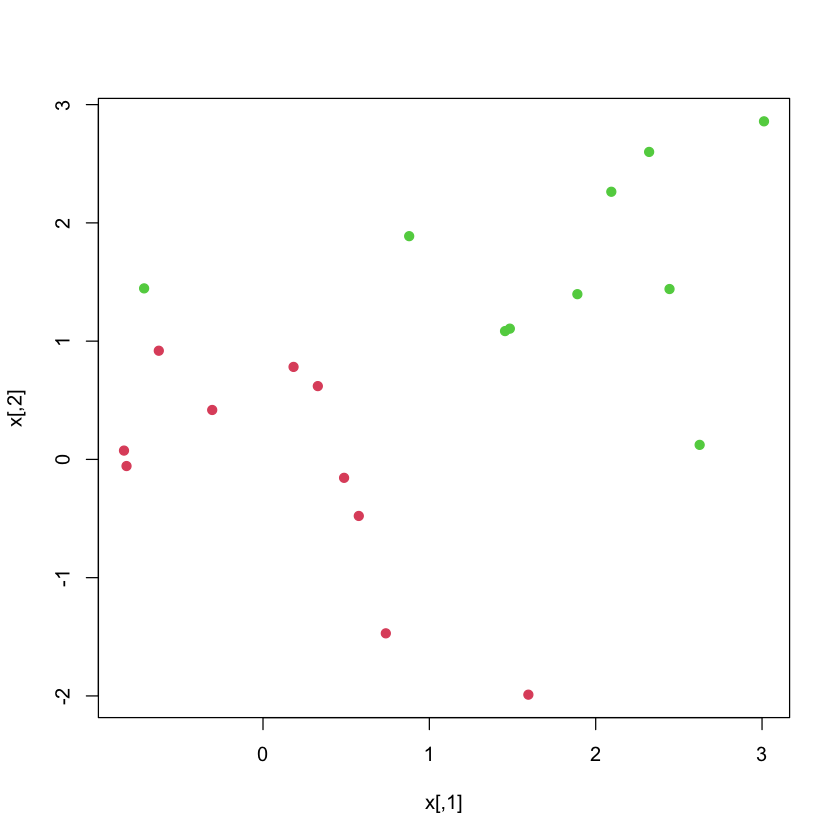

In [11]:
# Make the classes (barely) linearly separable
x[y == 1, ] <- x[y == 1, ] + 0.5
plot(x, col = (y + 5) / 2, pch = 19)


Call:
svm(formula = y ~ ., data = dat, kernel = "linear", cost = 1e+05)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  1e+05 

Number of Support Vectors:  3

 ( 1 2 )


Number of Classes:  2 

Levels: 
 -1 1




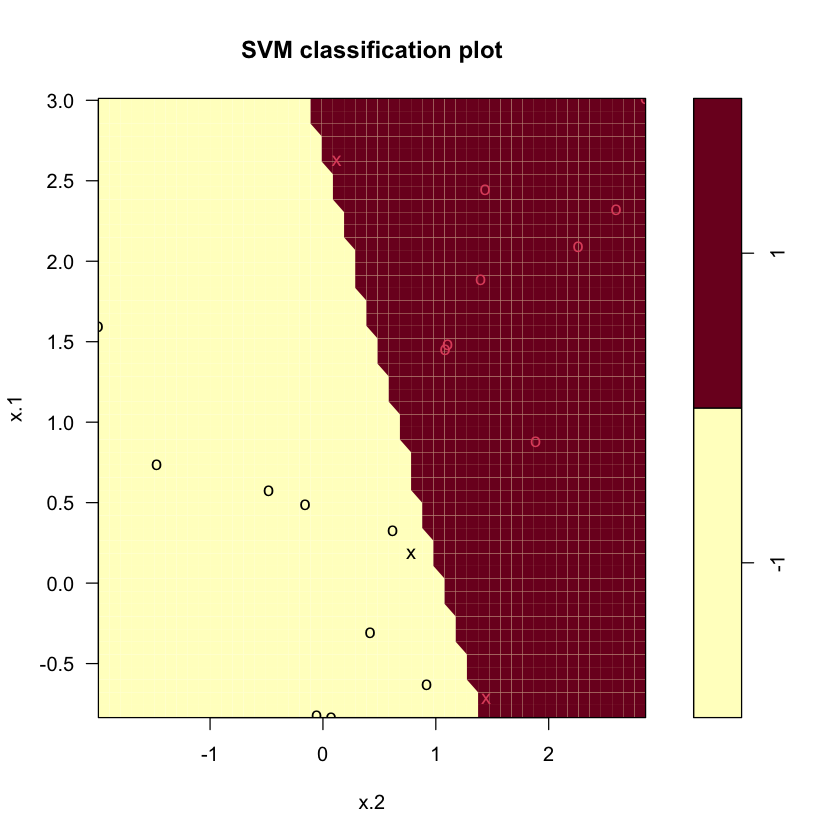

In [12]:
# Very large cost: no training errors, narrow margin
dat <- data.frame(x = x, y = as.factor(y))
svmfit <- svm(y ~ ., data = dat, kernel = "linear", cost = 1e5)
summary(svmfit)
plot(svmfit, dat)


Call:
svm(formula = y ~ ., data = dat, kernel = "linear", cost = 1)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  linear 
       cost:  1 

Number of Support Vectors:  7

 ( 4 3 )


Number of Classes:  2 

Levels: 
 -1 1




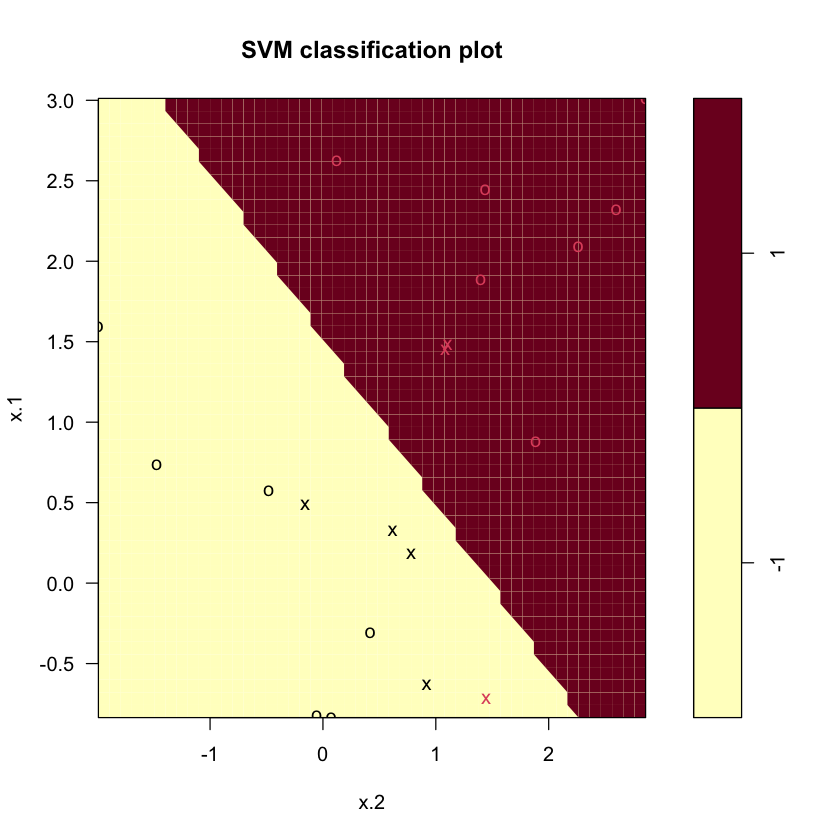

In [13]:
# cost = 1: one training error, wider margin
svmfit <- svm(y ~ ., data = dat, kernel = "linear", cost = 1)
summary(svmfit)
plot(svmfit, dat)

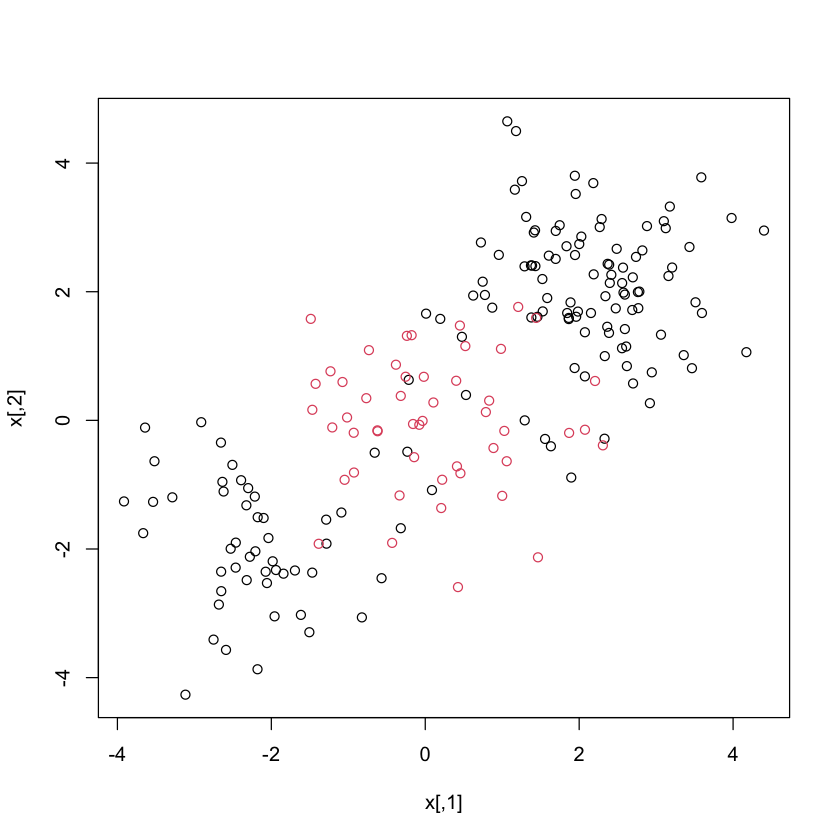

In [14]:
# 9.6.2 Support Vector Machine: data with a non-linear class boundary
set.seed(1)
x <- matrix(rnorm(200 * 2), ncol = 2)
x[1:100, ] <- x[1:100, ] + 2
x[101:150, ] <- x[101:150, ] - 2
y <- c(rep(1, 150), rep(2, 50))
dat <- data.frame(x = x, y = as.factor(y))
plot(x, col = y)


Call:
svm(formula = y ~ ., data = dat[train, ], kernel = "radial", gamma = 1, 
    cost = 1)


Parameters:
   SVM-Type:  C-classification 
 SVM-Kernel:  radial 
       cost:  1 

Number of Support Vectors:  31

 ( 16 15 )


Number of Classes:  2 

Levels: 
 1 2




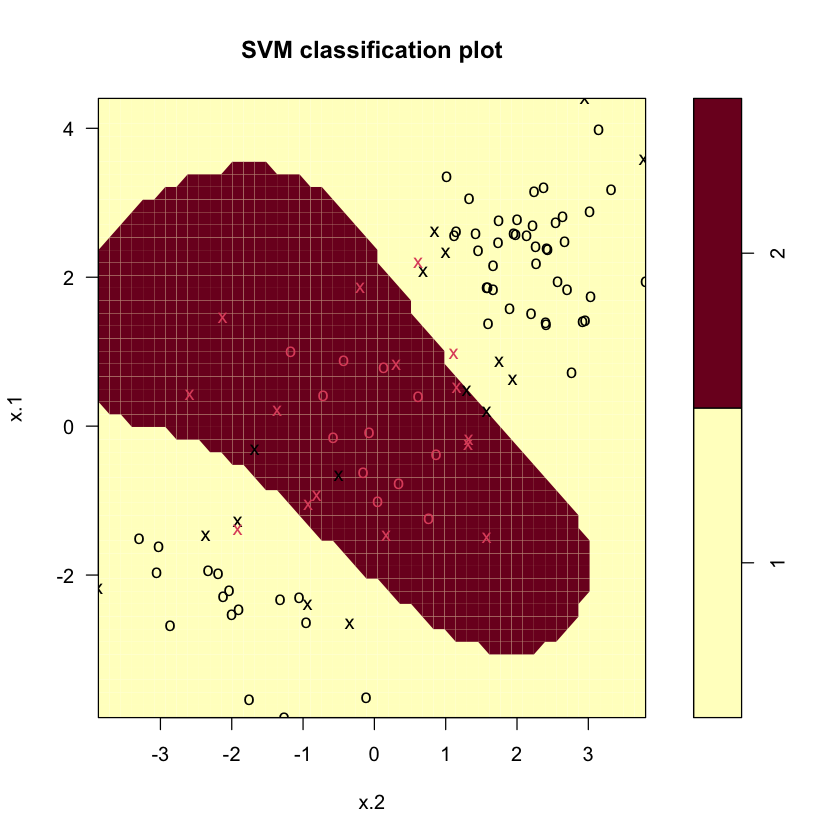

In [15]:
# Radial kernel, gamma = 1, cost = 1
train <- sample(200, 100)
svmfit <- svm(y ~ ., data = dat[train, ], kernel = "radial", gamma = 1, cost = 1)
plot(svmfit, dat[train, ])
summary(svmfit)

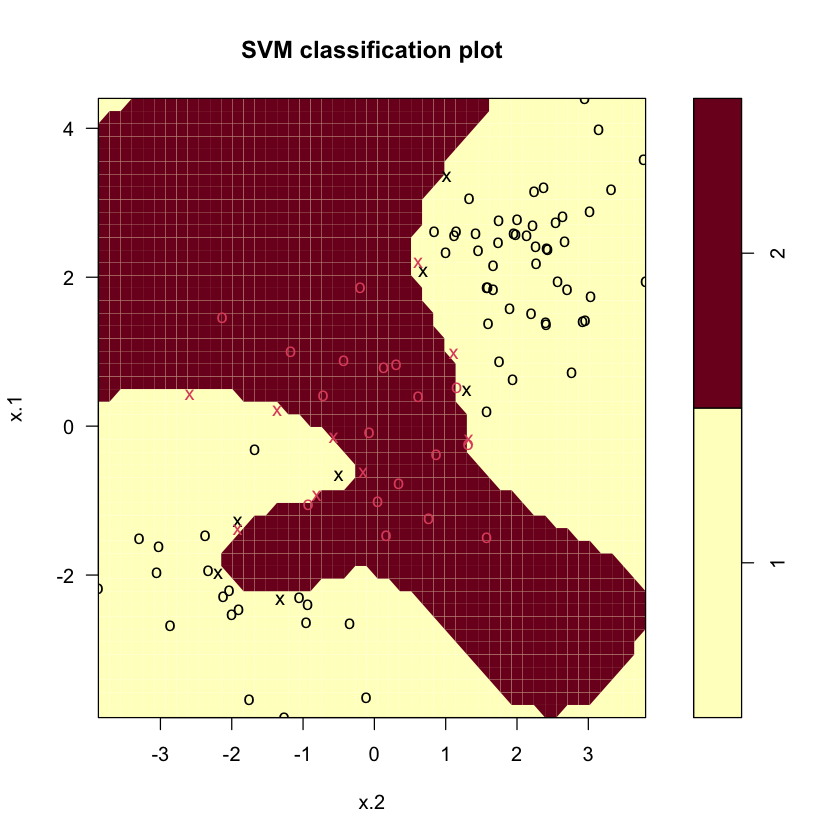

In [16]:
# Larger cost: fewer training errors, more irregular boundary
svmfit <- svm(y ~ ., data = dat[train, ], kernel = "radial", gamma = 1, cost = 1e5)
plot(svmfit, dat[train, ])

In [17]:
# Cross-validate over cost and gamma
set.seed(1)
tune.out <- tune(svm, y ~ ., data = dat[train, ], kernel = "radial",
                 ranges = list(cost = c(0.1, 1, 10, 100, 1000),
                               gamma = c(0.5, 1, 2, 3, 4)))
summary(tune.out)


Parameter tuning of ‘svm’:

- sampling method: 10-fold cross validation 

- best parameters:
 cost gamma
    1   0.5

- best performance: 0.07 

- Detailed performance results:
    cost gamma error dispersion
1  1e-01   0.5  0.26 0.15776213
2  1e+00   0.5  0.07 0.08232726
3  1e+01   0.5  0.07 0.08232726
4  1e+02   0.5  0.14 0.15055453
5  1e+03   0.5  0.11 0.07378648
6  1e-01   1.0  0.22 0.16193277
7  1e+00   1.0  0.07 0.08232726
8  1e+01   1.0  0.09 0.07378648
9  1e+02   1.0  0.12 0.12292726
10 1e+03   1.0  0.11 0.11005049
11 1e-01   2.0  0.27 0.15670212
12 1e+00   2.0  0.07 0.08232726
13 1e+01   2.0  0.11 0.07378648
14 1e+02   2.0  0.12 0.13165612
15 1e+03   2.0  0.16 0.13498971
16 1e-01   3.0  0.27 0.15670212
17 1e+00   3.0  0.07 0.08232726
18 1e+01   3.0  0.08 0.07888106
19 1e+02   3.0  0.13 0.14181365
20 1e+03   3.0  0.15 0.13540064
21 1e-01   4.0  0.27 0.15670212
22 1e+00   4.0  0.07 0.08232726
23 1e+01   4.0  0.09 0.07378648
24 1e+02   4.0  0.13 0.14181365
25 1e+03   4.0  0.15 0

In [18]:
# Test-set predictions from the best model
table(true = dat[-train, "y"],
      pred = predict(tune.out$best.model, newdata = dat[-train, ]))

    pred
true  1  2
   1 67 10
   2  2 21